# Dataset B — Aos Fatos (arquivo de checagens): EDA descritiva

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 2 do roteiro de trabalho.

**Fonte real dos dados:** [aosfatos.org/noticias/?formato=checagem](https://www.aosfatos.org/noticias/?formato=checagem), o arquivo público de checagens da agência Aos Fatos, filtrado por 3 tags editoriais reais:

| Tag pesquisada | Cobertura coletada | Nº de itens |
|---|---|---|
| `inteligencia-artificial` | população completa (11/11 páginas) | 122 |
| `eleicoes-2026` | população completa (1/1 página) | 12 |
| `eleicoes-2022` | população completa (35/35 páginas) | 419 |

Total: **553 checagens reais**, coletadas via navegação real (Claude in Chrome) em 23/08/2026, em duas etapas: uma coleta inicial de 7 páginas de `eleicoes-2022`, depois ampliada para as 35 páginas completas a pedido do usuário. Três páginas (13, 27 e 31) retornaram, na primeira tentativa, conteúdo idêntico ao da página anterior — um glitch de cache do próprio site já visto antes — e foram recarregadas com sucesso antes de aceitas; nenhuma foi inventada ou preenchida por extrapolação. Nenhum dado sintético foi usado neste dataset.

**Por que este dataset é metodologicamente mais forte que o Dataset A para H1/H2/H4:** o Aos Fatos rotula editorialmente cada checagem com **veredito** e **tema**, incluindo o tema `inteligência artificial` de forma explícita — ou seja, aqui `rotulo_grupo` (IA vs. Tradicional) é uma **classificação humana da própria fonte jornalística**, não uma heurística de regex como no Dataset A.

**Limitação honesta:** a extração de texto desta listagem **não expõe a data de publicação de cada checagem** (o layout mostra veredito/tema/título, mas a data fica em um elemento que não foi capturado nesta passada). Por isso, este dataset **não suporta diretamente H3 (sobrevivência/tempo até desmentido) nem H5 (aceleração temporal)** sem uma coleta complementar item a item — ponto registrado explicitamente na seção de limitações.


In [1]:

import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)


## 1. Carga dos dados reais

In [2]:

df = pd.read_csv("../data/raw/dataset_b_aosfatos.csv", keep_default_na=False)
print(f"Linhas: {len(df)} | Colunas: {list(df.columns)}")
df.head(3)


Linhas: 553 | Colunas: ['id_checagem_af', 'titulo', 'veredito', 'tema', 'tag_pesquisa', 'fonte']


,id_checagem_af,titulo,veredito,tema,tag_pesquisa,fonte
0,AF-0001,Vídeos em que Tancredo e Ulysses criticam Bolsonaro são obra de IA,falso,inteligência artificial,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem
1,AF-0002,É falso que Lula disse que teve perna amputada em 2023,falso,boataria política,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem
2,AF-0003,Vídeo de IA circula em posts como se mostrasse desabamento na Colômbia,falso,exploração de tragédia,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem


## 2. Limpeza e tratamento de valores ausentes

`veredito` e `tema` vêm como string vazia (`""`) quando o Aos Fatos não rotulou aquele campo — tratado como categoria explícita `"(não informado)"`, nunca preenchido com um valor inventado.

In [3]:

for col in ["veredito", "tema"]:
    n_vazio = (df[col] == "").sum()
    print(f"{col}: {n_vazio} vazios de {len(df)} ({n_vazio/len(df)*100:.1f}%)")

df["veredito"] = df["veredito"].replace("", "(não informado)")
df["tema"] = df["tema"].replace("", "(não informado)")

dup = df.duplicated(subset=["titulo"]).sum()
print(f"\nTítulos duplicados: {dup}")
if dup:
    display(df[df.duplicated(subset=['titulo'], keep=False)].sort_values('titulo')[['titulo', 'tag_pesquisa']])


veredito: 32 vazios de 553 (5.8%)
tema: 413 vazios de 553 (74.7%)

Títulos duplicados: 0


## 3. Engenharia de features

### 3.1 Rótulo de grupo (IA vs. Tradicional) — classificação editorial real, não heurística

In [4]:

df["rotulo_grupo"] = np.where(df["tag_pesquisa"] == "inteligencia-artificial", "IA", "Tradicional")
df["rotulo_grupo"].value_counts()


rotulo_grupo
Tradicional    431
IA             122
Name: count, dtype: int64

### 3.2 Vetor de mídia (heurística sobre o título)
O Aos Fatos não expõe o formato da peça checada (texto/imagem/áudio/vídeo) como coluna própria nesta listagem — inferimos por palavras-chave no título, um sinal textual real (não fabricado), documentando a taxa de indeterminação.

In [5]:

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text.lower()).strip()

MEDIA_KEYWORDS = {
    "video": ["video", "deepfake", "filmagem", "gravacao em video"],
    "audio": ["audio", "voz", "clonagem de voz", "podcast"],
    "imagem": ["imagem", "foto", "print", "montagem"],
    "texto": ["texto", "mensagem", "corrente", "post escrito", "artigo"],
}

def vetor_midia(titulo_norm):
    for vetor, kws in MEDIA_KEYWORDS.items():
        if any(kw in titulo_norm for kw in kws):
            return vetor
    return "indeterminado"

df["titulo_norm"] = df["titulo"].map(normalize_text)
df["vetor_midia"] = df["titulo_norm"].map(vetor_midia)
df["vetor_midia"].value_counts()


vetor_midia
indeterminado    297
video            191
imagem            47
audio              9
texto              9
Name: count, dtype: int64

### 3.3 Alvo do ataque (heurística sobre o título)

In [6]:

ATTACK_KEYWORDS = {
    "candidato_pessoa": ["carater", "honestidade", "vida pessoal", "familia", "saude",
                          "corrupcao pessoal", "traicao", "diploma", "patrimonio pessoal",
                          "morte", "morreu", "lula", "bolsonaro", "candidato", "candidata"],
    "urna_processo": ["urna", "biometria", "totalizacao", "apuracao", "sistema eletronico",
                       "fraude eleitoral", "codigo-fonte", "codigo fonte", "seguranca do voto",
                       "tse", "eleicao", "eleicoes", "voto"],
}

def alvo_ataque(titulo_norm):
    score_p = sum(kw in titulo_norm for kw in ATTACK_KEYWORDS["candidato_pessoa"])
    score_u = sum(kw in titulo_norm for kw in ATTACK_KEYWORDS["urna_processo"])
    if score_p == 0 and score_u == 0:
        return "indeterminado"
    return "candidato_pessoa" if score_p >= score_u else "urna_processo"

df["alvo_ataque"] = df["titulo_norm"].map(alvo_ataque)
df["alvo_ataque"].value_counts()


alvo_ataque
candidato_pessoa    297
indeterminado       173
urna_processo        83
Name: count, dtype: int64

## 4. EDA descritiva

In [7]:

print("=== Veredito por grupo ===")
print(pd.crosstab(df["rotulo_grupo"], df["veredito"]))

print("\n=== Distribuição de tag_pesquisa ===")
print(df["tag_pesquisa"].value_counts())


=== Veredito por grupo ===
veredito      (não informado)  discurso oficial  distorcido  falso  \
rotulo_grupo                                                         
IA                          1                 0           0    121   
Tradicional                31                 1           6    349   

veredito      não é bem assim  
rotulo_grupo                   
IA                          0  
Tradicional                44  

=== Distribuição de tag_pesquisa ===
tag_pesquisa
eleicoes-2022              419
inteligencia-artificial    122
eleicoes-2026               12
Name: count, dtype: int64


In [8]:

print("=== Temas mais comuns dentro do grupo IA (classificação editorial real) ===")
temas_ia = df.loc[df["rotulo_grupo"] == "IA", "tema"].value_counts()
print(temas_ia)


=== Temas mais comuns dentro do grupo IA (classificação editorial real) ===
tema
boataria política          48
inteligência artificial    40
exploração de tragédia     15
(não informado)             9
fraudes digitais            4
eleições 2024               3
políticas públicas          1
autoritarismo               1
tecnopolítica               1
Name: count, dtype: int64


### 4.1 H2 (preview) — Vetor de mídia por grupo IA vs. Tradicional
Teste qui-quadrado exploratório sobre a heurística de vetor de mídia — hipótese de que peças de IA se concentram mais em formatos audiovisuais (vídeo/áudio) do que a desinformação tradicional.

In [9]:

tabela_midia = pd.crosstab(df["rotulo_grupo"], df["vetor_midia"])
print(tabela_midia)

chi2, p, dof, _ = stats.chi2_contingency(tabela_midia)
n = tabela_midia.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabela_midia.shape) - 1)))
print(f"\nQui-quadrado: chi2={chi2:.3f}, p={p:.4f}, gl={dof}, V de Cramér={v_cramer:.3f}")

pct_audiovisual = (
    df.assign(audiovisual=df["vetor_midia"].isin(["video", "audio"]))
    .groupby("rotulo_grupo")["audiovisual"].mean().mul(100).round(1)
)
print("\n% de peças audiovisuais (vídeo+áudio) por grupo:\n", pct_audiovisual)


vetor_midia   audio  imagem  indeterminado  texto  video
rotulo_grupo                                            
IA                2      27             36      1     56
Tradicional       7      20            261      8    135

Qui-quadrado: chi2=57.773, p=0.0000, gl=4, V de Cramér=0.323

% de peças audiovisuais (vídeo+áudio) por grupo:
 rotulo_grupo
IA             47.5
Tradicional    32.9
Name: audiovisual, dtype: float64


### 4.2 H4 (preview) — Alvo do ataque por grupo

In [10]:

tabela_alvo = pd.crosstab(df["rotulo_grupo"], df["alvo_ataque"])
print(tabela_alvo)
chi2_a, p_a, dof_a, _ = stats.chi2_contingency(tabela_alvo)
print(f"\nQui-quadrado: chi2={chi2_a:.3f}, p={p_a:.4f}, gl={dof_a}")


alvo_ataque   candidato_pessoa  indeterminado  urna_processo
rotulo_grupo                                                
IA                          46             76              0
Tradicional                251             97             83

Qui-quadrado: chi2=79.077, p=0.0000, gl=2


## 5. Visualizações

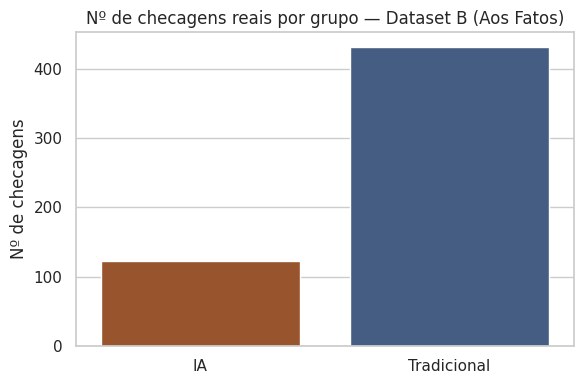

In [11]:

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="rotulo_grupo", hue="rotulo_grupo",
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, legend=False, ax=ax)
ax.set_title("Nº de checagens reais por grupo — Dataset B (Aos Fatos)")
ax.set_xlabel(""); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


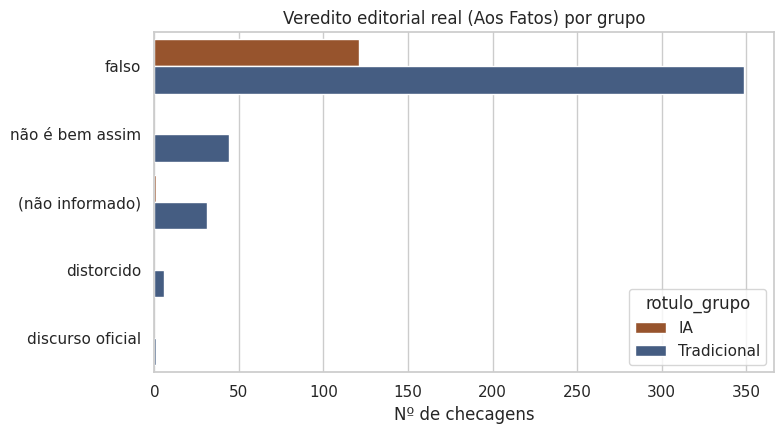

In [12]:

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="veredito", hue="rotulo_grupo", order=df["veredito"].value_counts().index,
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)
ax.set_title("Veredito editorial real (Aos Fatos) por grupo")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


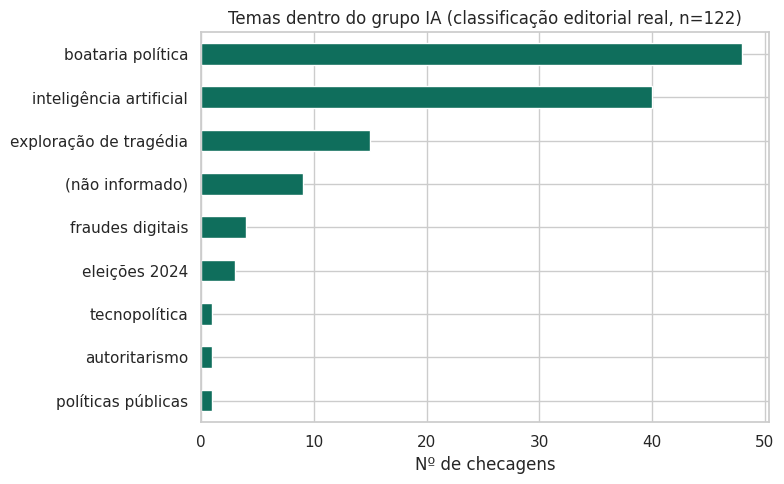

In [13]:

fig, ax = plt.subplots(figsize=(8, 5))
temas_ia.sort_values().plot(kind="barh", color="#0F6E5C", ax=ax)
ax.set_title('Temas dentro do grupo IA (classificação editorial real, n=122)')
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


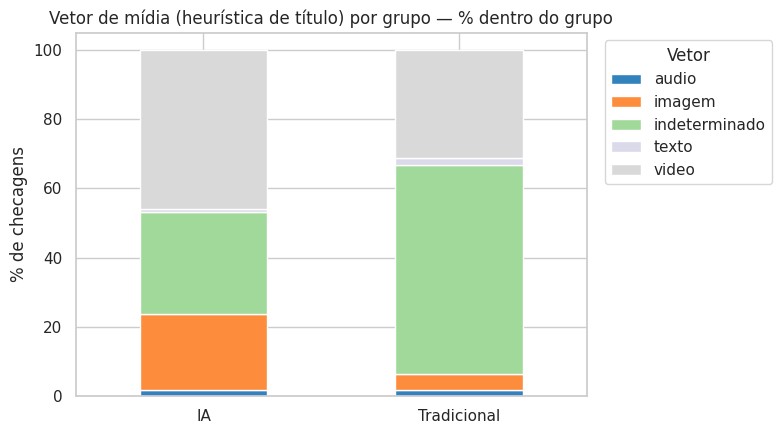

In [14]:

fig, ax = plt.subplots(figsize=(8, 4.5))
midia_pct = pd.crosstab(df["rotulo_grupo"], df["vetor_midia"], normalize="index").mul(100)
midia_pct.plot(kind="bar", stacked=True, colormap="tab20c", ax=ax)
ax.set_title("Vetor de mídia (heurística de título) por grupo — % dentro do grupo")
ax.set_xlabel(""); ax.set_ylabel("% de checagens"); ax.legend(title="Vetor", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()


## 6. Comparação com a heurística do Dataset A (validação cruzada informal)

In [15]:

try:
    df_a = pd.read_csv("../data/processed/dataset_a_fato_ou_boato_enriquecido.csv")
    pct_ia_a = (df_a["rotulo_ia_bin"] == "IA").mean() * 100
    pct_ia_b = (df["rotulo_grupo"] == "IA").mean() * 100
    print(f"Dataset A — % rotulado IA pela heurística de regex: {pct_ia_a:.1f}% (n={len(df_a)})")
    print(f"Dataset B — % rotulado IA pela tag editorial real do Aos Fatos: {pct_ia_b:.1f}% (n={len(df)})")
    print("\nNota: os denominadores não são diretamente comparáveis (recortes de tags distintos),")
    print("mas a diferença de magnitude sinaliza que a heurística do Dataset A provavelmente")
    print("SUBESTIMA a real prevalência de desinformação assistida por IA — mais um motivo para")
    print("priorizar o Dataset B (rótulo editorial) nos testes formais de H1/H2/H4 na Fase 3.")
except FileNotFoundError:
    print("Rode antes o notebook 01 para gerar ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv")


Dataset A — % rotulado IA pela heurística de regex: 0.0% (n=322)
Dataset B — % rotulado IA pela tag editorial real do Aos Fatos: 22.1% (n=553)

Nota: os denominadores não são diretamente comparáveis (recortes de tags distintos),
mas a diferença de magnitude sinaliza que a heurística do Dataset A provavelmente
SUBESTIMA a real prevalência de desinformação assistida por IA — mais um motivo para
priorizar o Dataset B (rótulo editorial) nos testes formais de H1/H2/H4 na Fase 3.


## 7. Salvar dataset enriquecido

In [16]:

df.drop(columns=["titulo_norm"]).to_csv("../data/processed/dataset_b_aosfatos_enriquecido.csv", index=False)
print("Salvo: ../data/processed/dataset_b_aosfatos_enriquecido.csv —", len(df), "linhas")
df.drop(columns=["titulo_norm"]).sample(5, random_state=7)


Salvo: ../data/processed/dataset_b_aosfatos_enriquecido.csv — 553 linhas


,id_checagem_af,titulo,veredito,tema,tag_pesquisa,fonte,rotulo_grupo,vetor_midia,alvo_ataque
308,AF-0309,PT não propôs em 2022 criar assembleia constituinte e descriminalizar drogas,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,indeterminado
339,AF-0340,É falso que urnas foram substituídas no Japão por mostrar número 13 em vez de 22,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,urna_processo
273,AF-0274,"É falso que campanha de Bolsonaro gastou só R$ 2,5 milhões e não anunciou no Google",falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,candidato_pessoa
51,AF-0052,Governo não anunciou salário mínimo de R$ 1.820 para 2026,falso,boataria política,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem,IA,indeterminado,indeterminado
172,AF-0173,"Homem que planejou atentado a bomba disse à polícia ser bolsonarista, não petista",falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,indeterminado


## 8. Limitações e próximos passos

- **Sem data de publicação por item nesta coleta.** Impede o cálculo direto de `dias_para_eleicao` e de latência de desmentido (H3) e de aceleração temporal (H5) neste dataset — necessário voltar ao Aos Fatos e capturar a data (visível em cada página individual de checagem, não na listagem) antes da Fase 3, ou cruzar por título com o Dataset C.
- **`eleicoes-2022` agora é população completa** (419 de 419 itens, 35/35 páginas) — a amostra de 7 páginas usada na primeira versão deste notebook foi substituída por uma coleta integral a pedido do usuário. Três páginas (13, 27, 31) exigiram nova tentativa por um glitch de cache do site que repetia o conteúdo da página anterior; cada uma foi confirmada como conteúdo único antes de aceita, e a checagem de duplicidade de títulos no dataset final (Seção 2) não encontrou nenhuma duplicata.
- **`vetor_midia` e `alvo_ataque` continuam heurísticos** (baseados só no título) — apenas `rotulo_grupo` (IA vs. Tradicional) e `veredito`/`tema` são classificação editorial real e confiável nesta fonte.
- Próximo passo natural: consolidar A + B no **Dataset C (unificado)**, cruzando por similaridade de título/tema, o que também ajuda a preencher datas ausentes do Dataset B via correspondência com itens do Dataset A que tratam do mesmo boato.
